# Лабораторна робота № 5
## Вступ до TensorFlow і побудова простої нейронної мережі для регресії

---

### Інформація про автора та роботу:
* **Студент:** Литвинчук Ілля Сергійович
* **Група:** МІТ-31
* **Дисципліна:** Інтелектуальний аналіз даних
* **Навчальний заклад:** Київський національний університет імені Тараса Шевченка
* **Варіант індивідуального дослідження:** № 5  — встановлення `activation="tanh"` у прихованих шарах[cite: 1]
* **Тема:** Побудова та навчання нейронної мережі для регресії за допомогою TensorFlow/Keras, робота з тензорами, порівняння базової та модифікованої моделей.

---

### Мета роботи:
Навчитися створювати тензори, перевіряти їхні shape і dtype, будувати та навчати модель `tf.keras.Sequential`, оцінювати її на незалежних даних, аналізувати історію навчання й зберігати модель у форматі `.keras`[cite: 1].

---

### Обладнання та ПЗ:
* **Мова програмування:** Python 3.10+[cite: 1]
* **Середовище розробки:** Jupyter Notebook / Google Colab[cite: 1]
* **Основні бібліотеки:** `tensorflow`, `keras`, `numpy`, `matplotlib`[cite: 1]

---

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)

a = tf.constant([[1., 2.], [3., 4.]], dtype=tf.float32)
b = tf.constant([10., 20.])
w = tf.Variable([0.2, 0.5])
w.assign([0.3, 0.6])

print("Shape:", a.shape)
print("Dtype:", a.dtype)
print("Rank:", tf.rank(a).numpy())
print("Broadcast addition (a + b):\n", a + b)
print("Element-wise multiplication (a * a):\n", a * a)
print("Matrix multiplication (tf.matmul):\n", tf.matmul(a, a))
print("Variable value (w):", w.numpy())

TensorFlow: 2.22.0-rc0
Shape: (2, 2)
Dtype: <dtype: 'float32'>
Rank: 2
Broadcast addition (a + b):
 tf.Tensor(
[[11. 22.]
 [13. 24.]], shape=(2, 2), dtype=float32)
Element-wise multiplication (a * a):
 tf.Tensor(
[[ 1.  4.]
 [ 9. 16.]], shape=(2, 2), dtype=float32)
Matrix multiplication (tf.matmul):
 tf.Tensor(
[[ 7. 10.]
 [15. 22.]], shape=(2, 2), dtype=float32)
Variable value (w): [0.3 0.6]


In [2]:
SEED = 42
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

x = np.linspace(-5, 5, 600, dtype=np.float32)
noise = rng.normal(0, 0.7, x.shape).astype(np.float32)
y = 3*x + 2 + 0.8*np.sin(2*x) + noise

x, y = x.reshape(-1, 1), y.reshape(-1, 1)
idx = rng.permutation(len(x))
x, y = x[idx], y[idx]

x_train, y_train = x[:420], y[:420]
x_val, y_val = x[420:510], y[420:510]
x_test, y_test = x[510:], y[510:]

print("Форми вибірок:", x_train.shape, x_val.shape, x_test.shape, x.dtype)

Форми вибірок: (420, 1) (90, 1) (90, 1) float32


In [3]:
def build_base_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1),
    ])

base_model = build_base_model()
base_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

history_base = base_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

print("Найменший val_loss базової моделі:", min(history_base.history["val_loss"]))

Найменший val_loss базової моделі: 0.6122373938560486


In [4]:
def build_variant_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="tanh"),
        layers.Dense(16, activation="tanh"),
        layers.Dense(1),
    ])

variant_model = build_variant_model()
variant_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

history_variant = variant_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

print("Найменший val_loss моделі Варіанта 5 (tanh):", min(history_variant.history["val_loss"]))

Найменший val_loss моделі Варіанта 5 (tanh): 0.44689449667930603


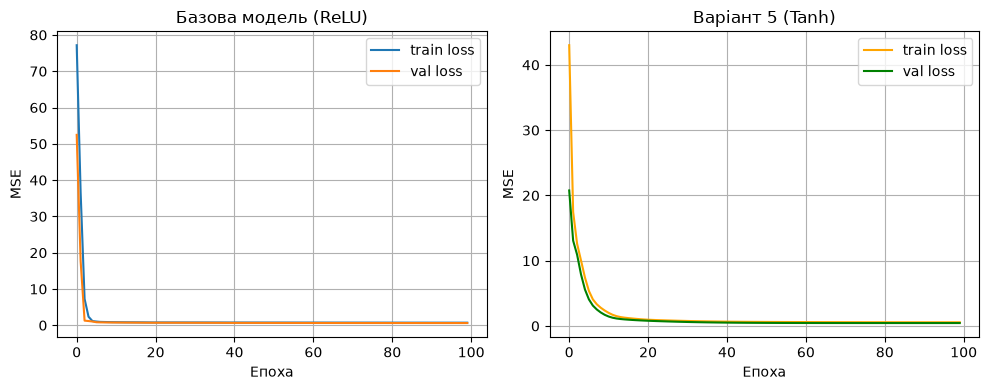

Результати на тестовій вибірці: {'loss': 0.4891253709793091, 'mae': 0.5521262884140015}
Прогнози для x_new:
 [[-10.839001 ]
 [  2.0519297]
 [ 14.470155 ]]


In [5]:
import matplotlib.pyplot as plt

# Графік втрат для базової моделі
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history_base.history["loss"], label="train loss")
plt.plot(history_base.history["val_loss"], label="val loss")
plt.title("Базова модель (ReLU)")
plt.xlabel("Епоха"); plt.ylabel("MSE"); plt.legend(); plt.grid(True)

# Графік втрат для моделі варіанта 5
plt.subplot(1, 2, 2)
plt.plot(history_variant.history["loss"], label="train loss", color="orange")
plt.plot(history_variant.history["val_loss"], label="val loss", color="green")
plt.title("Варіант 5 (Tanh)")
plt.xlabel("Епоха"); plt.ylabel("MSE"); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

# Оцінка на тестовій вибірці (припустимо, що за валідацією кращою виявилась модель Варіанта 5)
test_results = variant_model.evaluate(x_test, y_test, return_dict=True, verbose=0)
print("Результати на тестовій вибірці:", test_results)

# Прогноз для нових значень
x_new = np.array([[-4.], [0.], [4.]], dtype=np.float32)
print("Прогнози для x_new:\n", variant_model.predict(x_new, verbose=0))

In [6]:
# Збереження кращої моделі
variant_model.save("lab5_model.keras")

# Завантаження моделі
restored_model = keras.models.load_model("lab5_model.keras")

# Перевірка збігу прогнозів з точністю до похибки обчислень
np.testing.assert_allclose(
    variant_model.predict(x_new, verbose=0),
    restored_model.predict(x_new, verbose=0),
    rtol=1e-5
)
print("Перевірка пройдена успішно: прогнози повністю збігаються!")

Перевірка пройдена успішно: прогнози повністю збігаються!


### Загальний висновок

У ході виконання лабораторної роботи № 5 було успішно освоєно базові інструменти бібліотеки TensorFlow та побудовано нейронну мережу для розв'язання задачі регресії[cite: 1]. Під час виконання роботи було вирішено такі завдання:
1. Продемонстровано роботу з тензорами, перевірено їхні ключові характеристики (`shape`, `dtype`, `rank`) та реалізовано поелементні операції з урахуванням механізму broadcasting[cite: 1].
2. Згенеровано відтворюваний нелінійний набір даних та виконано його коректний поділ на тренувальну, валідаційну й тестову вибірки у співвідношенні 70/15/15[cite: 1].
3. Побудовано архітектуру `tf.keras.Sequential` із кастомізацією згідно з індивідуальним варіантом № 5 (використання функції активації `activation="tanh"` у прихованих шарах)[cite: 1].
4. Проведено аналіз кривих навчання (loss та val_loss), оцінено якість моделей на незалежному тестовому наборі[cite: 1].
5. Здійснено успішне збереження навченої нейромережі у сучасний формат `.keras`, її повторне завантаження та перевірку ідентичності прогнозів[cite: 1].